# Analysis of the validation split results

The same analysis as `analysis.ipynb`, run on the held-out validation split.

In [1]:
import os
from pathlib import Path

from IPython.display import Image, display

from grant_eval.analysis import contrasts as con
from grant_eval.analysis import dataset as ds
from grant_eval.analysis import edgecases as ec
from grant_eval.analysis import errors as err
from grant_eval.analysis import fields as fld
from grant_eval.analysis import frontier as fr
from grant_eval.analysis import funders as fm
from grant_eval.analysis import generalisation as gen
from grant_eval.analysis import report
from grant_eval.analysis import sensitivity as sens
from grant_eval.analysis import telemetry as tel
from grant_eval.scoring.groundtruth import load_ground_truth

# nbconvert runs from the notebook folder, but the paths are relative to the repo root.
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

SCORED = Path("eval/scored/validation")
FIGURES = Path("eval/figures-validation")

## Provenance

In [2]:
data = ds.load_dataset(SCORED)
gt = load_ground_truth()
manifest = data.manifest

print(f"split(s) in this artefact: {', '.join(data.splits())}")
print(f"scorer source hash: {manifest['scorer']['source_hash']}")
print(f"scorer git sha: {manifest['scorer']['git']['sha']} "
      f"(dirty={manifest['scorer']['git']['dirty']})")
print()
print(f"scored runs: {manifest['counts']['n_scored']} "
      f"({manifest['counts']['n_configs']} configs, "
      f"{manifest['counts']['n_skipped']} skipped)")
print(f"funders: {len(data.funders())}")
for funder in data.funders():
    print(f"  {funder}")

split(s) in this artefact: validation
scorer source hash: 67c1b6e752f63eef61c6c7e0dde9d20838d230d8ecf146f65880b0962cc1b809
scorer git sha: e1d5f56bcbece523fdacc01f70fe691b3cf71e7d (dirty=True)

scored runs: 80 (2 configs, 0 skipped)
funders: 8
  Hakluyt Society
  National Lottery Heritage Fund
  PRS Foundation
  Royal Historical Society
  Society of Authors
  The Pathological Society of Great Britain and Ireland
  The Pilgrim Trust
  US-UK Fulbright Commission


In [3]:
# Prints the provenance, or raises if the tune and validation scorer hashes disagree.
rq6 = gen.tune_validation_gap(validation_scored_dir=SCORED)

print(f"lock                : {rq6.lock_path}")
print(f"locked at           : {rq6.locked_at}")
print(f"tune artefact       : {rq6.tune_scored_dir}")
print(f"validation artefact : {rq6.validation_scored_dir}")
print(f"one scorer across both: {rq6.source_hash}")
print()
print("locked configurations:")
for g in rq6.gaps:
    print(f"  {g.label}")

lock                : eval/locked-config.json
locked at           : 2026-09-19T21:37:24.143292+00:00
tune artefact       : eval/scored/grid
validation artefact : eval/scored/validation
one scorer across both: 67c1b6e752f63eef61c6c7e0dde9d20838d230d8ecf146f65880b0962cc1b809

locked configurations:
  openrouter/deepseek/deepseek-v4-flash-0731 | few_shot | t0.7
  openrouter/deepseek/deepseek-v4-flash-0731 | minimal | t0.7


## Scope and caveats

In [4]:
print(report.scope_notes(data, scored_dir=SCORED))

SCOPE
This report covers the 8 validation funders and their 69 in-scope ground-truth rows only.
This is the HELD-OUT split, run single-shot on the configurations locked in eval/locked-config.json before any validation page was fetched (preregistration §5). No configuration was chosen, tuned or discarded after seeing anything in this report, and none may be: the out-of-sample claim in the GENERALISATION section above is the whole return on that restraint and iterating here would spend it. The comparison against Pivot-RP remains OUT OF SCOPE — no Pivot-RP data exists in the repo to compare against.
Model, temperature and every prompt but the two locked ones are absent by construction, not by accident: the lock fixed them. Sections that need a second level of a fixed factor are marked 'not estimable on this split:' rather than omitted, so this report stays section-for-section comparable with the tune report at eval/figures/.
Funder type (D-F) and structural complexity (D-E) were both defi

## Leaderboard

In [5]:
print(report.leaderboard(data, scored_dir=SCORED))

LEADERBOARD — macro F1 across all 2 configurations, best first
    #  config                                                          macroF1   macroP   macroR  funders
    1  openrouter/deepseek/deepseek-v4-flash-0731 | few_shot | t0.7      0.786    0.865    0.754        8
    2  openrouter/deepseek/deepseek-v4-flash-0731 | minimal | t0.7       0.767    0.841    0.739        8


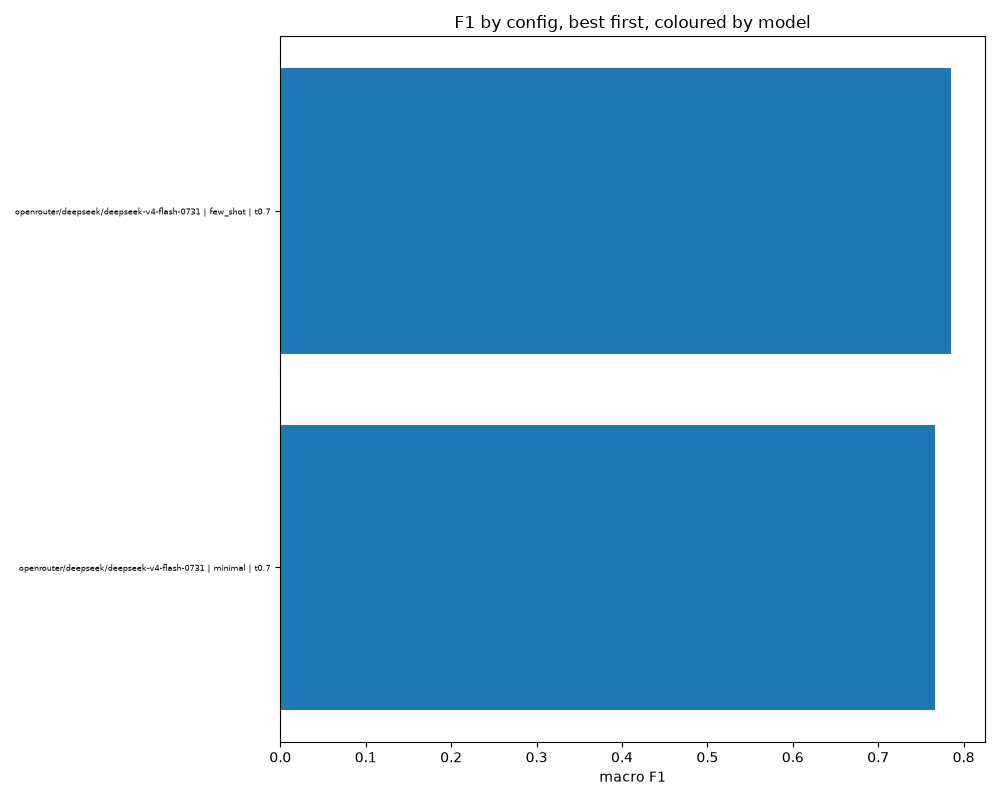

In [6]:
display(Image(filename=str(FIGURES / "f1_by_config.png")))

## What actually gets delivered

In [7]:
field_acc = fld.field_accuracy(data, gt, scored_dir=SCORED)
print(report.field_accuracy_table(field_acc))

STRUCTURED FIELD ACCURACY — exact match, pooled over opportunities; CONDITIONAL ON DETECTION (see 'n eval.')
  group                            deadlines   n eval.    amount_max_gbp   n eval.    amount_min_gbp   n eval.            status   n eval.
  deepseek-v4-flash-0731               0.563       485             0.939       426             0.927       436             0.932       502

A field is only scorable on an opportunity the run actually found, so these accuracies sit over different populations and are NOT a like-for-like ranking: the weakest model's figures rest on the easiest opportunities it reached. END-TO-END below puts detection and extraction on one denominator, where that selection effect cannot hide. Opportunities whose field the labeller could not establish (uncertain_fields) are excluded from both numerator and denominator.


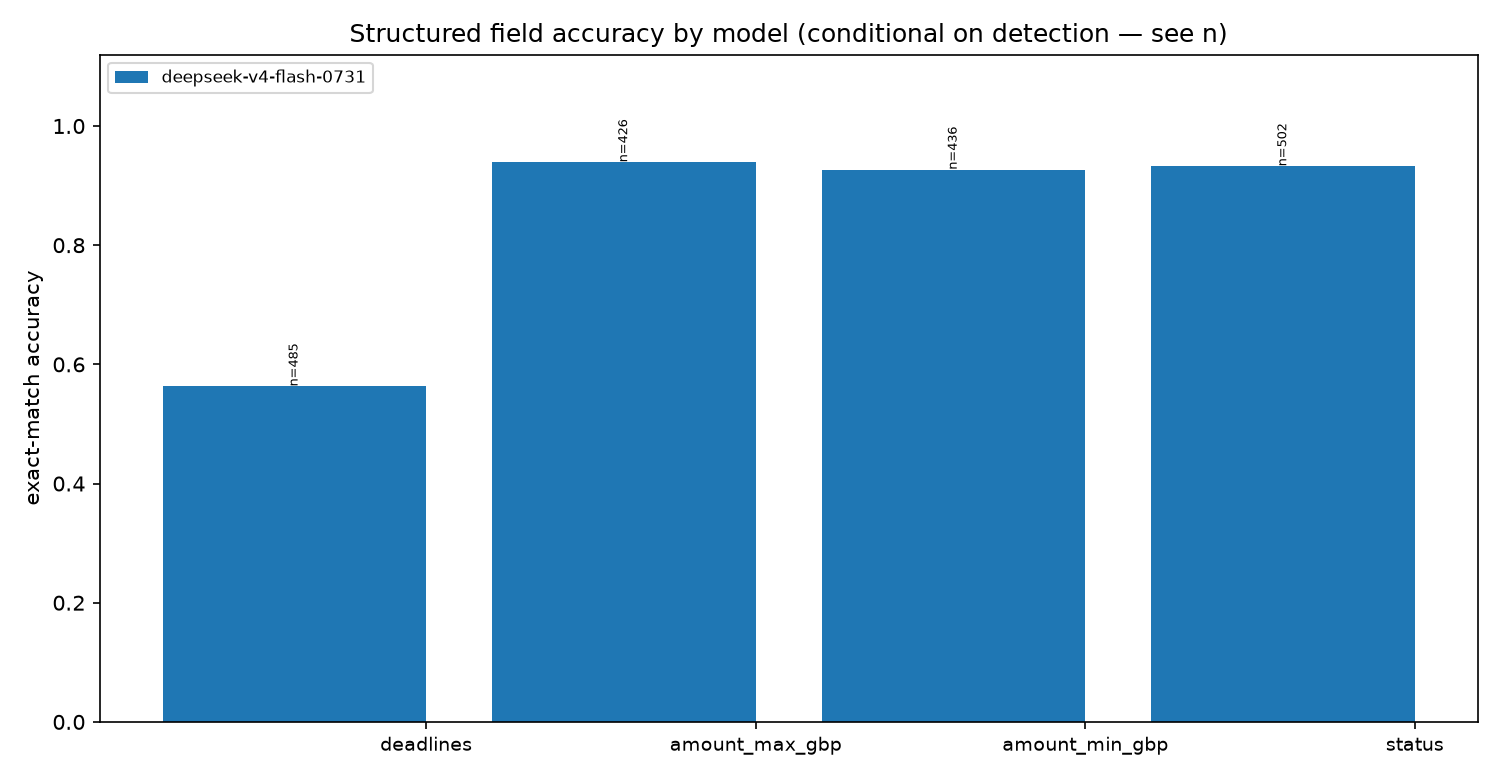

In [8]:
display(Image(filename=str(FIGURES / "field_accuracy.png")))

### Delivered results per config and per prompt strategy

In [9]:
print(report.field_by_config_table(fld.field_accuracy(data, gt, key="config", scored_dir=SCORED)))

STRUCTURED FIELD ACCURACY BY CONFIG — exact match; ordered by deadline accuracy; CONDITIONAL ON DETECTION
  config                                                                deadlines   amount_max_gbp   amount_min_gbp           status
  openrouter/deepseek/deepseek-v4-flash-0731 | minimal | t0.7               0.565            0.957            0.915            0.927
  openrouter/deepseek/deepseek-v4-flash-0731 | few_shot | t0.7              0.561            0.922            0.937            0.938

Denominators differ by config as well as by model — a config that found little is scored on the little it found — so read this beside the END-TO-END table, which puts detection and extraction on one denominator.


In [10]:
print(report.field_factor_table(fld.field_accuracy_by_factor(data, gt, "prompt", scored_dir=SCORED)))

STRUCTURED FIELD ACCURACY BY PROMPT, WITHIN MODEL — EXPLORATORY: no field-level contrast is pre-registered
  deepseek-v4-flash-0731
    prompt            deadlines       n   amount_max_gbp       n   amount_min_gbp       n           status       n
    few_shot              0.561     246            0.922     218            0.937     223            0.938     257
    minimal               0.565     239            0.957     208            0.915     213            0.927     245

The pre-registered contrasts (D-A) found no prompt effect on DETECTION F1. They say nothing about extraction, which is a different endpoint measured on a different population, and nothing here is a test — these are descriptive cells with unequal denominators, offered because the model-level table pools them away entirely.


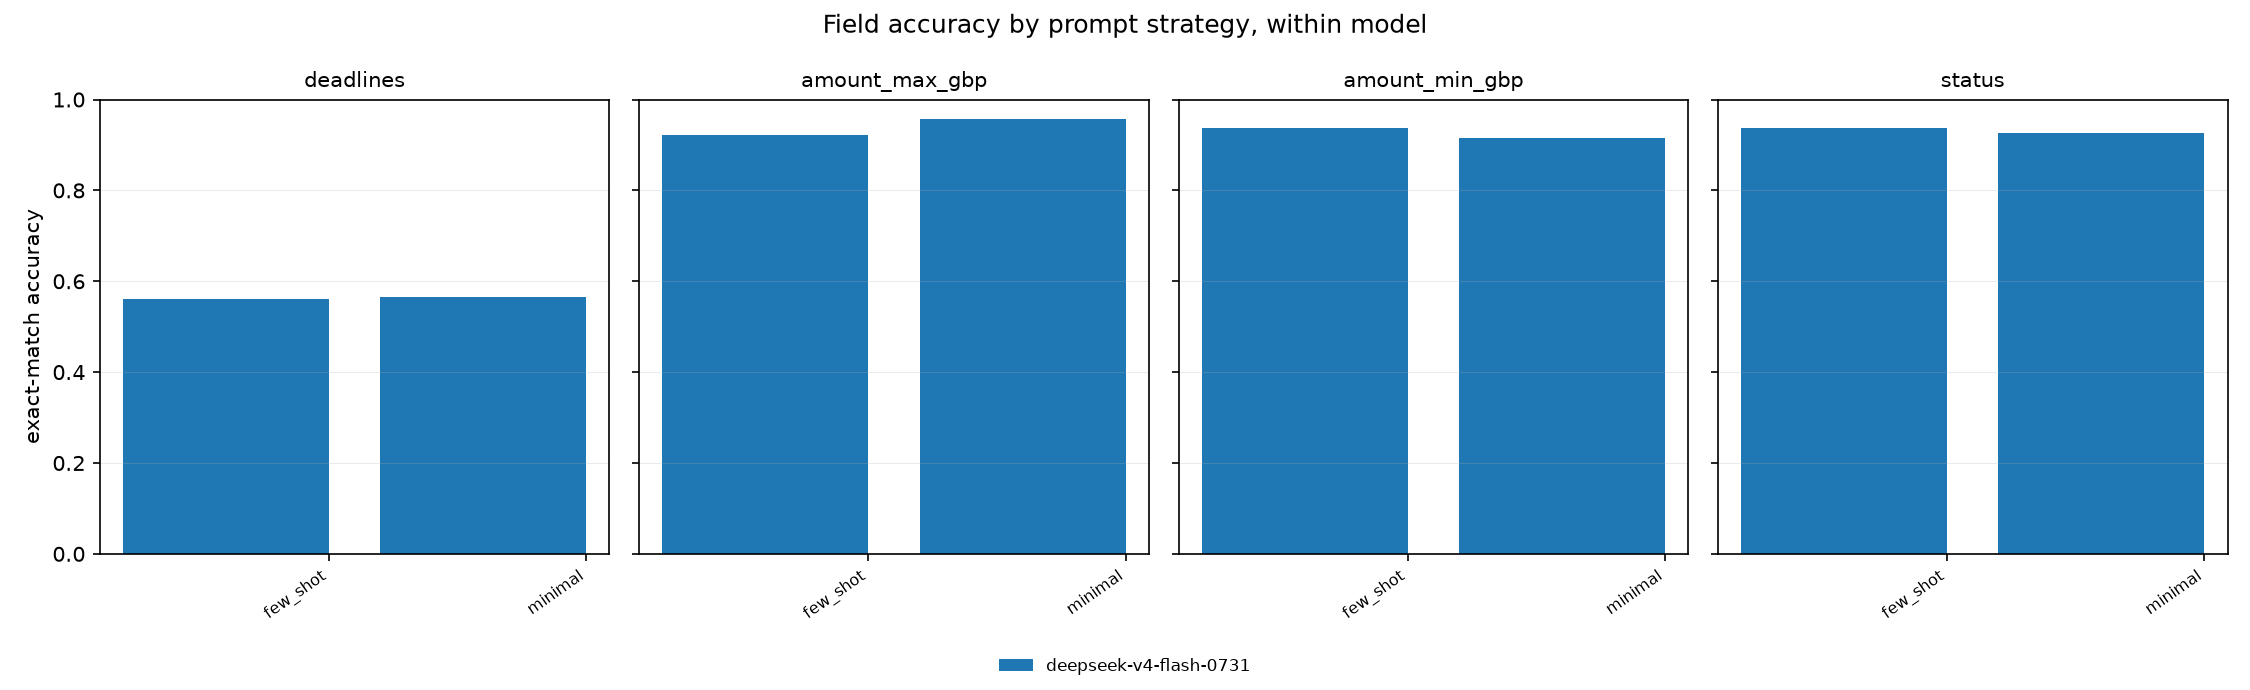

In [11]:
display(Image(filename=str(FIGURES / "field_by_prompt.png")))

## Which way the errors run

In [12]:
print(report.field_direction_table(fld.field_directions(data, scored_dir=SCORED)))

FIELD ERROR DIRECTION — 'asserted' = agent supplied a value the truth does not have; 'omitted' = agent left blank a value the truth has
  group                          deadlines asrt/omit  amount_max_gbp asrt/omit  amount_min_gbp asrt/omit          status asrt/omit
  deepseek-v4-flash-0731                       5 / 8                    0 / 26                   19 / 13                     0 / 0

The two are different product failures and one accuracy figure pools them: an asserted value is an invention a user may act on, an omission is a gap they can see. A field whose errors are overwhelmingly omissions is failing conservatively; one whose errors are assertions is not.


## End-to-end result

In [13]:
e2e_deadlines = fld.end_to_end_frontier(
    fld.end_to_end(data, gt, field="deadlines", scored_dir=SCORED)
)
print(report.end_to_end_table(e2e_deadlines))

END-TO-END RESULT (field = deadlines) — share of ALL in-scope opportunities both found AND correctly extracted; 56 opportunities, 13 excluded as uncertain
  config                                                          detected  end-to-end     gap   cost $   $/usable  frontier
  openrouter/deepseek/deepseek-v4-flash-0731 | minimal | t0.7        0.805       0.636  -0.168    0.175     0.0049       yes
  openrouter/deepseek/deepseek-v4-flash-0731 | few_shot | t0.7       0.815       0.611  -0.204    0.202     0.0059        no

An opportunity that was never found counts as a failure here, which is the point: you cannot extract a correct deadline from a grant you did not find. 'frontier' is the Pareto frontier over (realised cost, end-to-end rate), computed by the same domain-free `frontier.pareto_frontier` the F1 frontier uses — a config on the F1 frontier need not be on this one.


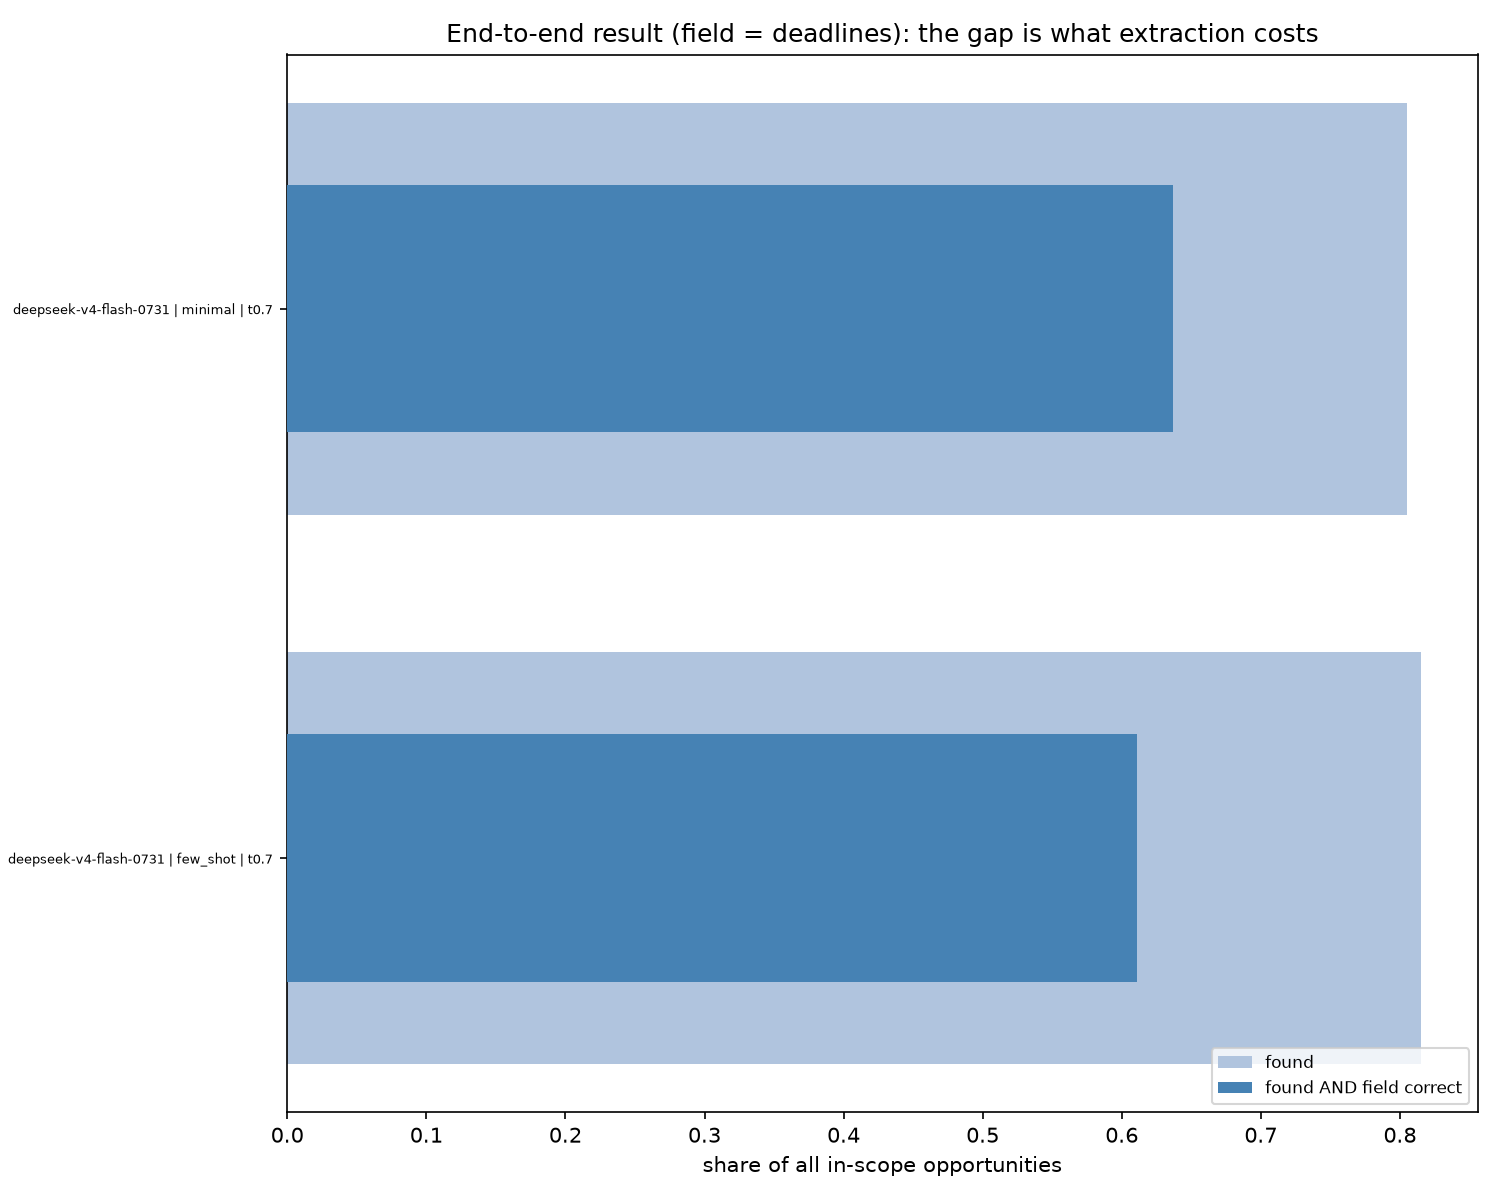

In [14]:
display(Image(filename=str(FIGURES / "end_to_end.png")))

## Best combination, and best for the money

In [15]:
e2e_all = fld.end_to_end_frontier(
    fld.end_to_end(data, gt, field="all", scored_dir=SCORED)
)
print(report.end_to_end_table(e2e_all))

END-TO-END RESULT (field = all) — share of ALL in-scope opportunities both found AND correctly extracted; 40 opportunities, 29 excluded as uncertain
  config                                                          detected  end-to-end     gap   cost $   $/usable  frontier
  openrouter/deepseek/deepseek-v4-flash-0731 | minimal | t0.7        0.868       0.463  -0.405    0.175     0.0095       yes
  openrouter/deepseek/deepseek-v4-flash-0731 | few_shot | t0.7       0.875       0.454  -0.421    0.202     0.0111        no

An opportunity that was never found counts as a failure here, which is the point: you cannot extract a correct deadline from a grant you did not find. 'frontier' is the Pareto frontier over (realised cost, end-to-end rate), computed by the same domain-free `frontier.pareto_frontier` the F1 frontier uses — a config on the F1 frontier need not be on this one.


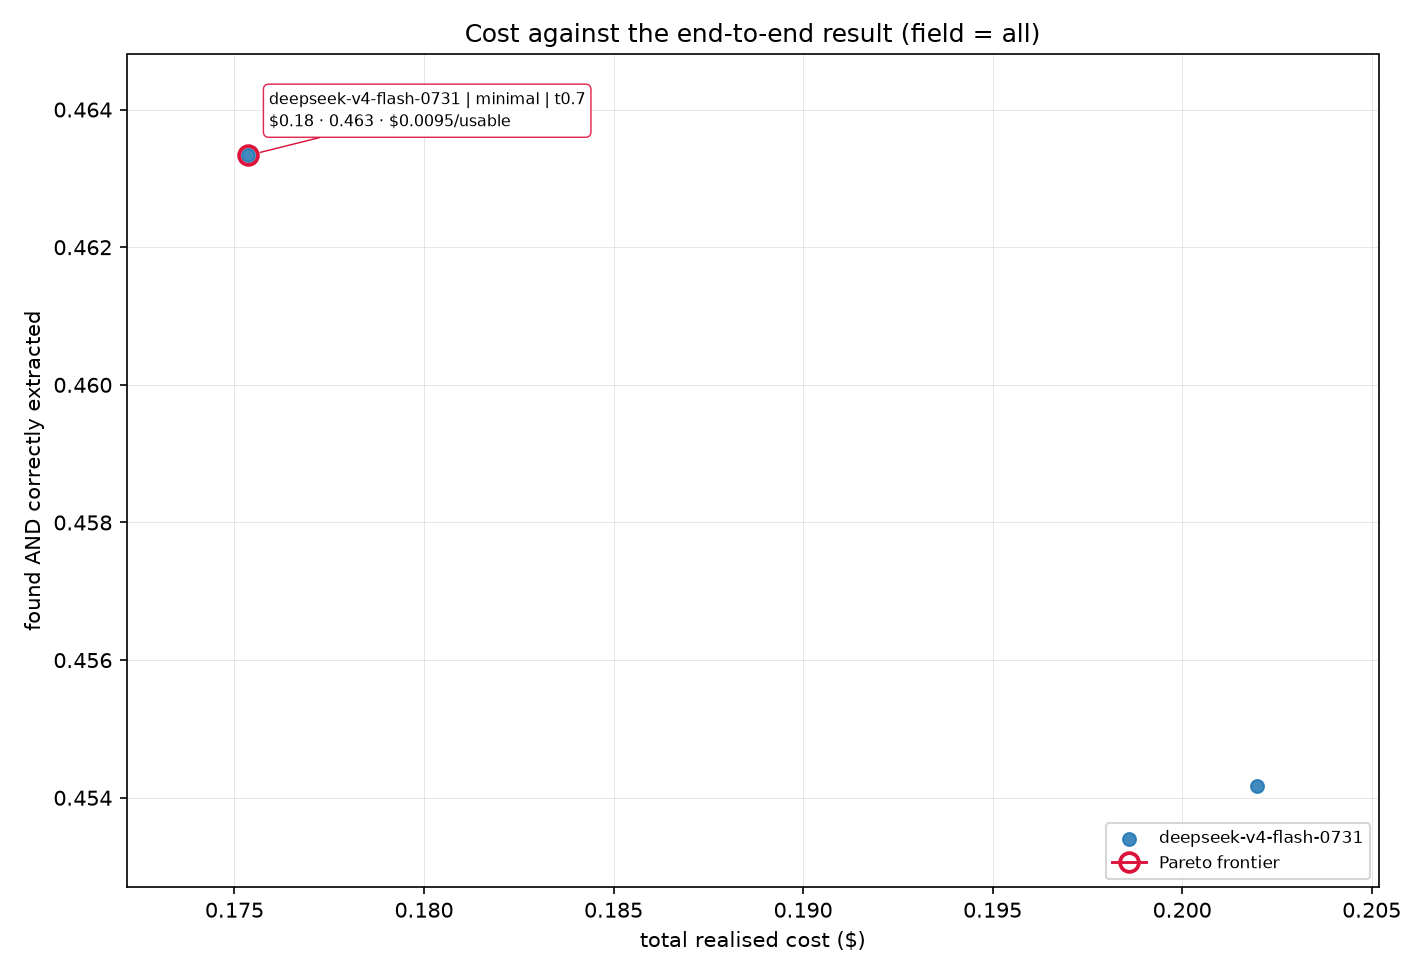

In [16]:
display(Image(filename=str(FIGURES / "end_to_end_frontier.png")))

## Per-funder detail for the top-ranked config

In [17]:
best_label = ds.config_label(
    "openrouter/deepseek/deepseek-v4-flash-0731", "few_shot", 0.7
)
print(report.per_funder_table(data, best_label, scored_dir=SCORED))

PER-FUNDER — openrouter/deepseek/deepseek-v4-flash-0731 | few_shot | t0.7
  funder                                                    n reps   prec    rec     F1  stable   kappa
  Hakluyt Society                                           1    5  1.000  1.000  1.000   1.000       —
  National Lottery Heritage Fund                            7    5  0.500  0.143  0.222   1.000   1.000
  PRS Foundation                                           10    5  1.000  0.940  0.968   0.900   0.113
  Royal Historical Society                                  8    5  0.846  0.700  0.763   1.000   0.762
  Society of Authors                                        5    5  1.000  1.000  1.000   1.000       —
  The Pathological Society of Great Britain and Ireland    26    5  0.978  1.000  0.989   1.000       —
  The Pilgrim Trust                                         5    5  0.910  0.680  0.771   0.750   0.724
  US-UK Fulbright Commission                                7    5  0.686  0.571  0.572   0.00

## Confirmatory contrasts

In [18]:
family = con.confirmatory_family(data)
print(report.contrast_table(family, fixed_factors=report.single_level_factors(data)))

CONFIRMATORY CONTRASTS (D-A) — pre-registered within-factor family, Holm-corrected together
  factor  level_a   level_b     mean d  median d  rank-biserial        p   Holm p     95% CI (n=8 clusters)  reject
  prompt  few_shot  minimal      0.019     0.013          0.524    0.312    0.312           [-0.039, 0.074]      no
  not estimable on this split: factor 'model' has a single level (openrouter/deepseek/deepseek-v4-flash-0731), so it contributes no within-factor contrast
  not estimable on this split: factor 'temperature' has a single level (0.7), so it contributes no within-factor contrast


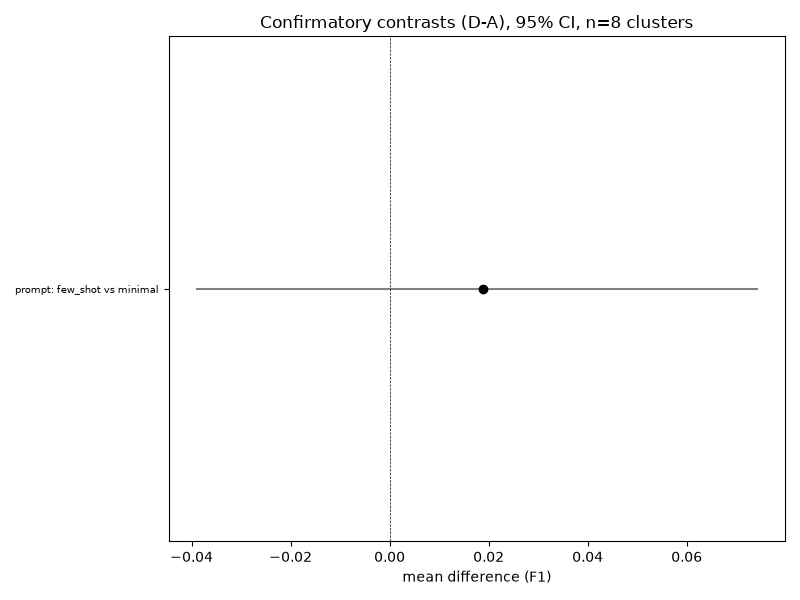

In [19]:
display(Image(filename=str(FIGURES / "contrasts.png")))

## Factor effects and the pre-registered interaction

In [20]:
print(report.interaction_note(data))

PRE-REGISTERED INTERACTION (D-B)
  not estimable on this split: factor 'model' has no level 'openrouter/amazon/nova-lite-v1' (present: openrouter/deepseek/deepseek-v4-flash-0731)
  not estimable on this split: factor 'prompt' has no level 'chain_of_thought' (present: few_shot, minimal)


In [21]:
print(report.temperature_note(data, family))

TEMPERATURE: MAIN EFFECT AND INTERACTION WITH MODEL
  not estimable on this split: factor 'temperature' has a single level (0.7), so there is no temperature contrast to correct
  not estimable on this split: factor 'model' has a single level (openrouter/deepseek/deepseek-v4-flash-0731), so there is no model pair to interact it with


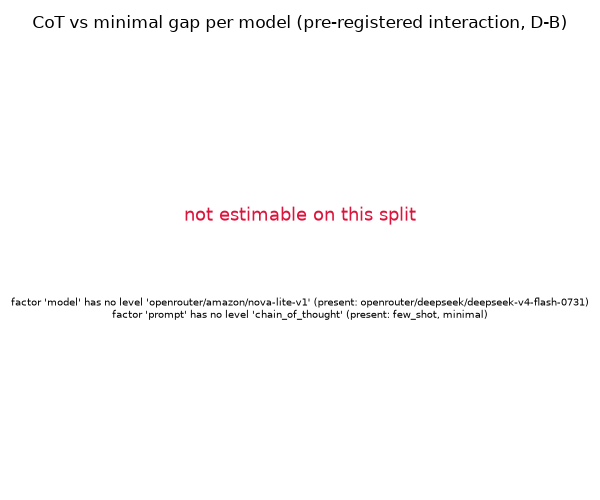

In [22]:
display(Image(filename=str(FIGURES / "interaction.png")))

## Reliability (RQ3)

In [23]:
print(report.reliability_table(data, scored_dir=SCORED))

RELIABILITY (RQ3) — mean stable-rate and mean Fleiss' kappa across funders, per config
  config                                                          stable-rate    kappa
  openrouter/deepseek/deepseek-v4-flash-0731 | few_shot | t0.7          0.831    0.475
  openrouter/deepseek/deepseek-v4-flash-0731 | minimal | t0.7           0.812    0.488


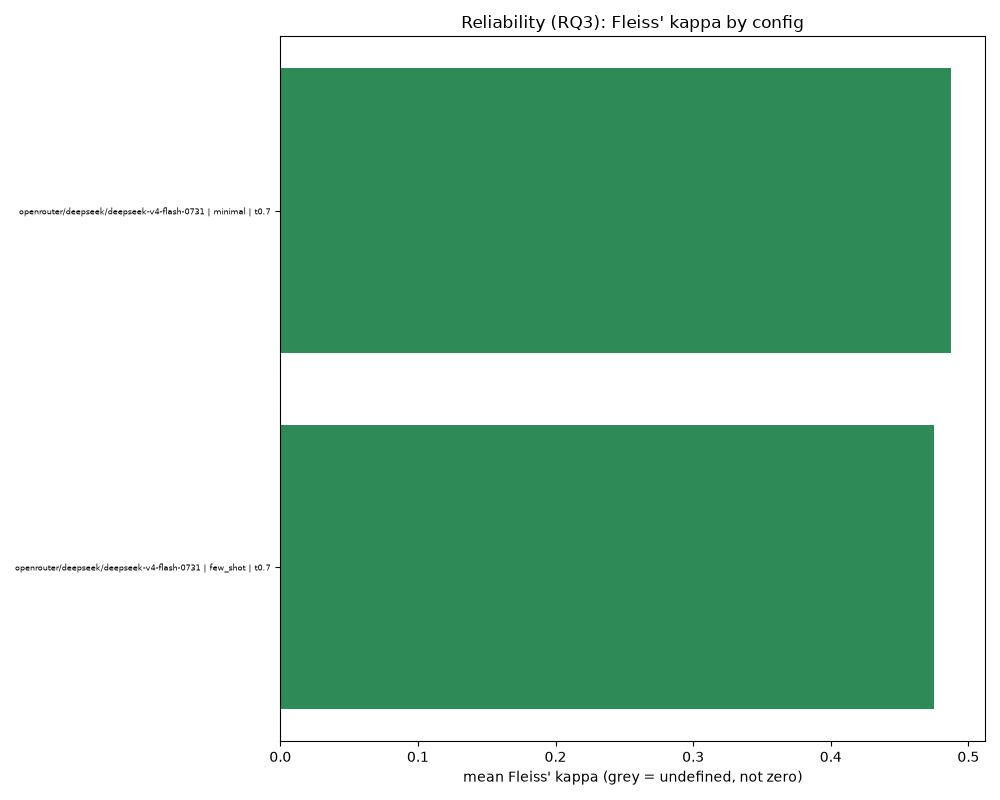

In [24]:
display(Image(filename=str(FIGURES / "reliability.png")))

## Strata

In [25]:
print(report.stratum_table(data, gt))

STRATA (D-C) — edge-case tags, validation-only row/cluster counts
  tag                       rows  clusters        status  reason
  rolling                      9         6   descriptive  9 rows (< 20) and 6 funder-clusters (< 8)
  multi_deadline              25         4   descriptive  4 funder-clusters (< 8)
  pdf_only                     2         2   descriptive  2 rows (< 20) and 2 funder-clusters (< 8)
  js_portal                    1         1   descriptive  1 rows (< 20) and 1 funder-clusters (< 8)
  ambiguous_eligibility        5         4   descriptive  5 rows (< 20) and 4 funder-clusters (< 8)
  restricted                  28         6   descriptive  6 funder-clusters (< 8)


## Do edge cases cost recall?

In [26]:
edge_contrasts = ec.tag_contrast_family(data, gt)
print(report.edge_case_table(edge_contrasts))

EDGE-CASE CONTRAST (D-C, extended) — mean recall on tagged rows MINUS mean recall on UNTAGGED rows, paired within funder; negative means the tag costs recall
  tag                           rows  tag clu.  paired clu.   tagged  untagged     diff              95% CI        status
  restricted                      28         6            2    0.942     0.440    0.502                   —   descriptive
  multi_deadline                  25         4            2    1.000     0.940    0.060                   —   descriptive
  rolling                          9         6            2    0.933     0.940   -0.007                   —   descriptive
  ambiguous_eligibility            5         4            1    0.900     0.880    0.020                   —   descriptive
  pdf_only                         2         2            0        —         —        —                   —   descriptive
  js_portal                        1         1            0        —         —        —                   —   

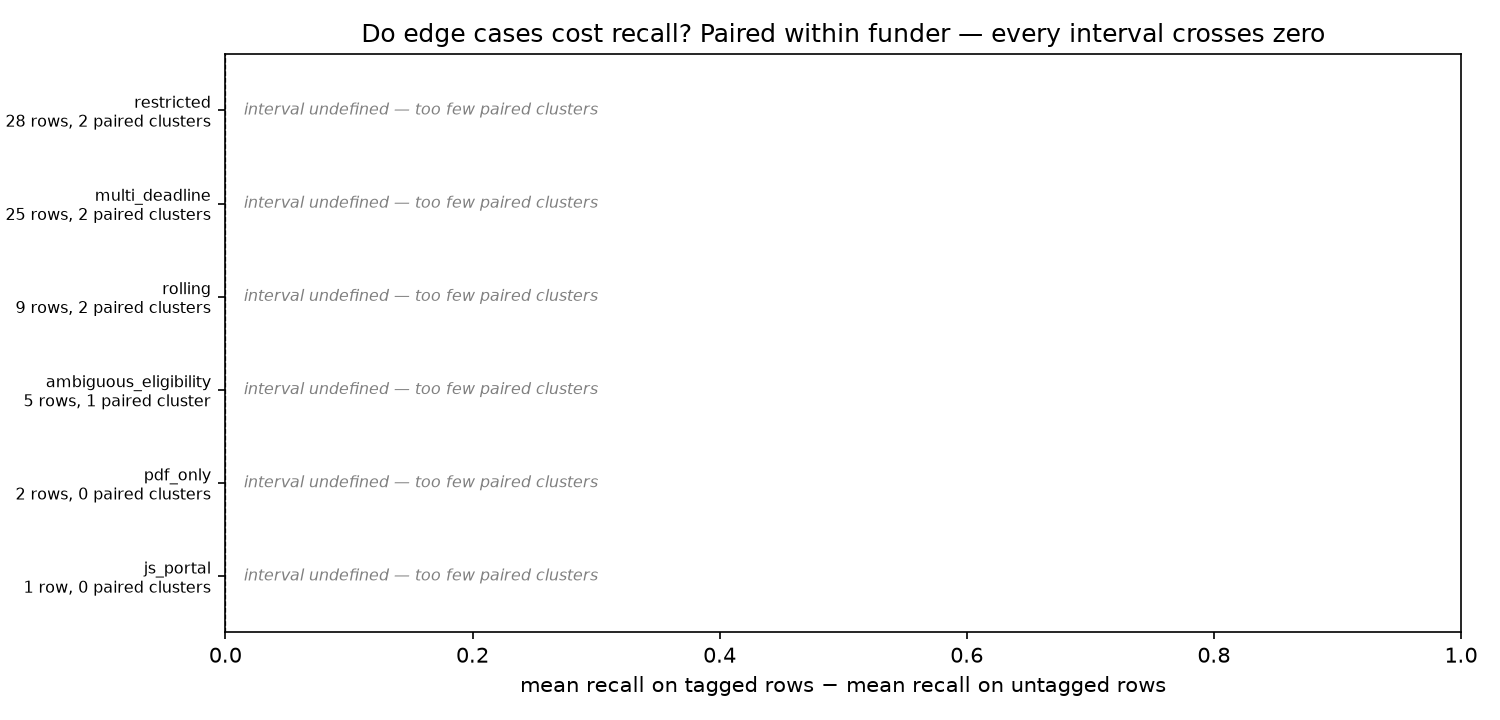

In [27]:
display(Image(filename=str(FIGURES / "edge_cases.png")))

## Why the tags cannot be read independently

In [28]:
print(report.tag_overlap_table(ec.tag_cooccurrence(gt, data.funders()),
                              split=data.splits()[0]))

EDGE-CASE TAG OVERLAP — in-scope validation rows carrying BOTH tags; the diagonal is the tag's own row count
  tag                      ambiguous_el     js_portal  multi_deadli      pdf_only    restricted       rolling
  ambiguous_eligibility               5             0             1             0             3             1
  js_portal                           0             1             0             1             1             0
  multi_deadline                      1             0            25             0             7             0
  pdf_only                            0             1             0             2             1             1
  restricted                          3             1             7             1            28             1
  rolling                             1             0             0             1             1             9

Where two tags share most of their rows, their marginal contrasts are substantially the same rows measured twice and can

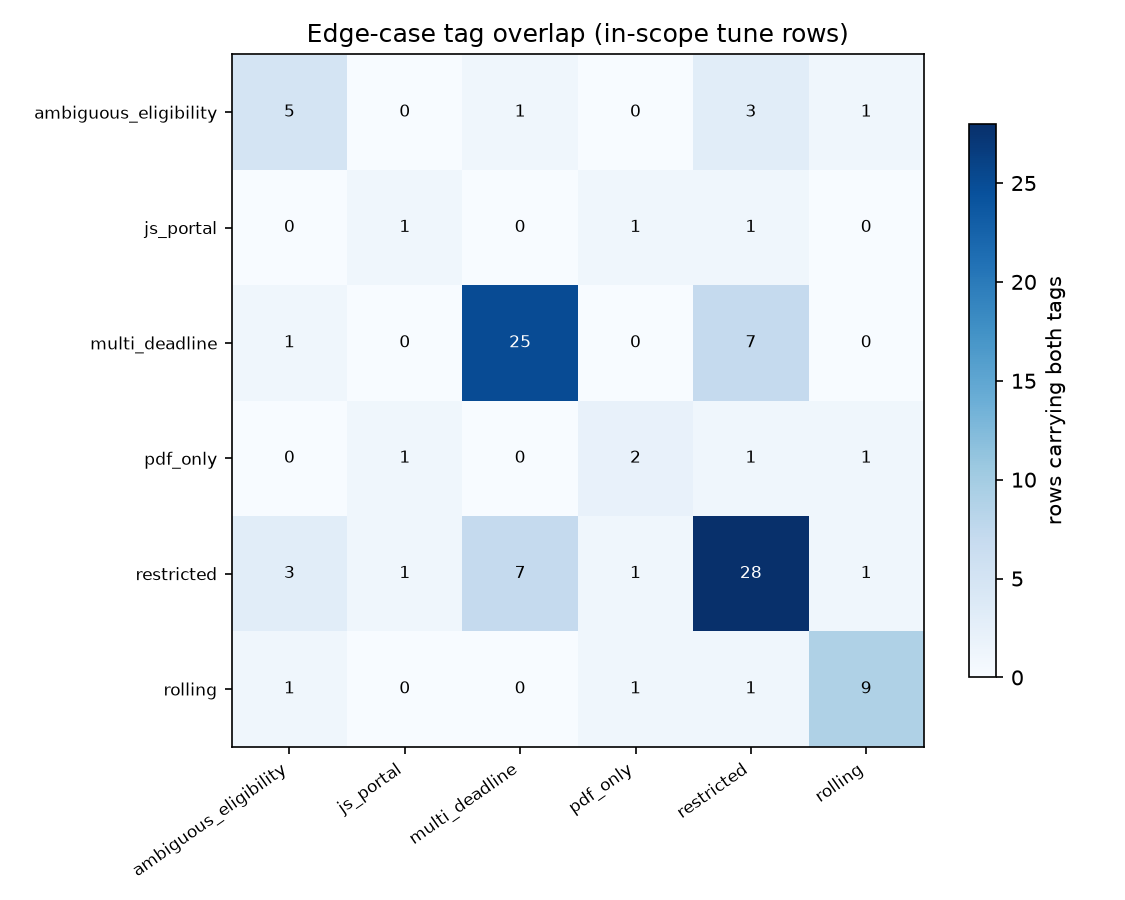

In [29]:
display(Image(filename=str(FIGURES / "edge_case_overlap.png")))

## Does stacking edge cases compound?

In [30]:
print(report.tag_count_table(ec.recall_by_tag_count(data, gt)))

RECALL BY EDGE-CASE COUNT — does stacking edge cases compound? EXPLORATORY: the bands were defined after seeing the tag distribution
  tags on row        rows  clusters  mean recall                95% CI
  0                    13         3        0.627      [+0.000, +1.000]
  1                    45         7        0.763      [+0.480, +0.980]
  2                     8         4        0.637      [+0.275, +1.000]
  3                     3         1        0.633                     —

Intervals here are on each band's own mean, not on a difference between bands, and they overlap: this table shows the shape, it does not test it.


## Edge cases hurt extraction, not detection

In [31]:
field_tags = [
    fld.field_accuracy_by_tag(data, gt, f, t, scored_dir=SCORED)
    for t in ("multi_deadline", "restricted", "rolling")
    for f in fld.FIELDS
]
print(report.field_by_tag_table(field_tags))

FIELD ACCURACY BY EDGE-CASE TAG — accuracy on tagged rows MINUS accuracy on UNTAGGED rows, paired within funder; negative means the tag costs accuracy
  tag             field              rows  paired clu.   tagged  untagged     diff              95% CI
  multi_deadline  deadlines            25            2    0.100     0.963   -0.863                   —
  multi_deadline  amount_max_gbp       25            2    0.937     1.000   -0.063                   —
  multi_deadline  amount_min_gbp       25            2    0.913     0.965   -0.052                   —
  multi_deadline  status               25            2    1.000     1.000    0.000                   —
  restricted      deadlines            28            1    0.900     0.925   -0.025                   —
  restricted      amount_max_gbp       28            1    1.000     1.000    0.000                   —
  restricted      amount_min_gbp       28            1    0.900     0.955   -0.055                   —
  restricted      status 

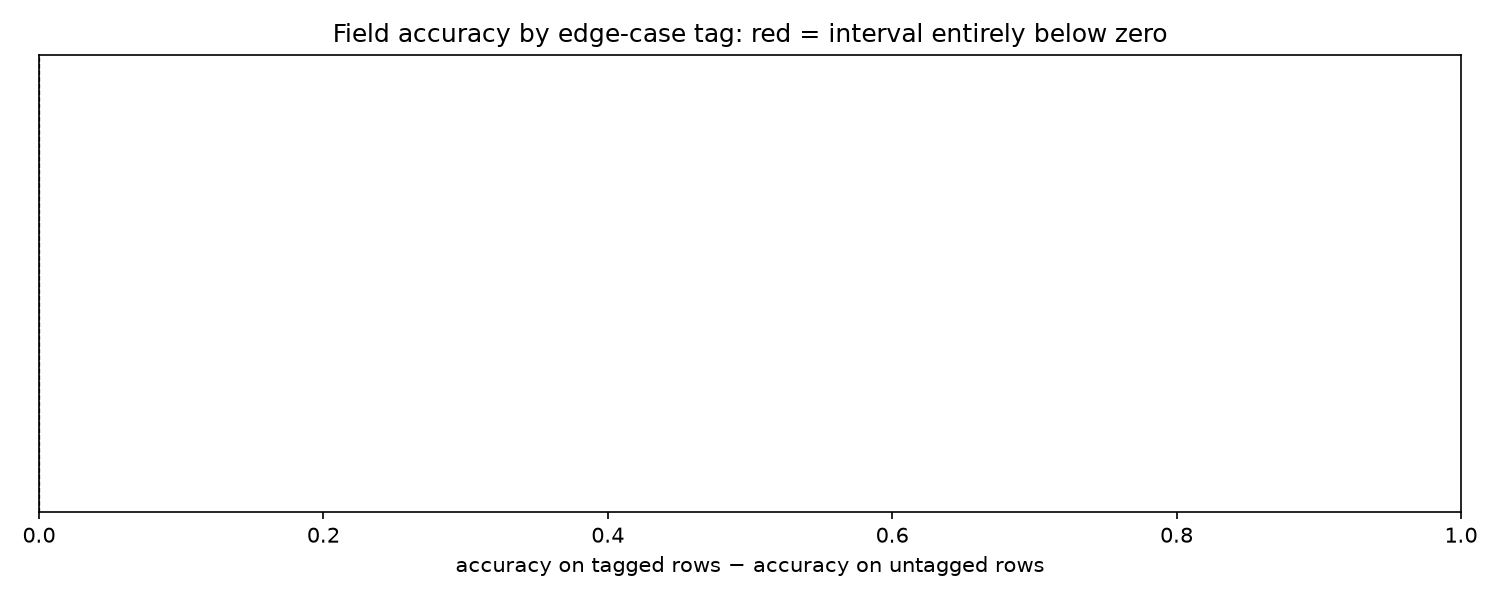

In [32]:
display(Image(filename=str(FIGURES / "field_by_tag.png")))

## Funder type (exploratory)

Not estimable on this split.

In [33]:
profiles = fm.load_profiles("validation")
print(report.funder_type_table(data, profiles))

FUNDER TYPE (D-F) — EXPLORATORY, defined after seeing the tune data; never statistically tested
  type_group         n_funders   mean F1 (all runs)
  not estimable on this split: no funder on this split carries a type group. `funders.TYPE_GROUPS` is validated to cover the tune split only (funders.load_profiles), deliberately: D-F was defined after seeing the tune data and bucketing a held-out funder into a post-hoc group would make an exploratory grouping look like a pre-registered one.


## Structural complexity (exploratory)

In [34]:
print(report.complexity_table(data, profiles))

STRUCTURAL COMPLEXITY (D-E) — rows_per_url; EXPLORATORY and partly a measurement artefact (see funders.py: the match key consults titles only on shared URLs, so a packed funder is exactly where paraphrase produces the largest false-positive class, ambiguous_title)
  funder                                                  rows/url          band   mean F1 (all runs)
  PRS Foundation                                              1.08  one_per_page                0.963
  US-UK Fulbright Commission                                  1.00  one_per_page                0.487
  Hakluyt Society                                             1.00  one_per_page                0.967
  National Lottery Heritage Fund                              1.00  one_per_page                0.222
  The Pathological Society of Great Britain and Ireland       1.00  one_per_page                0.981
  The Pilgrim Trust                                           1.00  one_per_page                0.840
  Royal Historical So

## Cost-effectiveness frontier

In [35]:
points = fr.cost_effectiveness(data)
print(report.frontier_table(points))

COST-EFFECTIVENESS FRONTIER — realised spend; P(frontier) is a funder-clustered bootstrap membership probability
  config                                                           cost $  macroF1 frontier  P(frontier) cost excl.
  openrouter/deepseek/deepseek-v4-flash-0731 | minimal | t0.7      0.1754    0.767      yes         1.00          0
  openrouter/deepseek/deepseek-v4-flash-0731 | few_shot | t0.7     0.2020    0.786      yes         0.74          0

'cost excl.' is how many of a config's runs died before billing (D-D) and so contributed nothing to its cost total above: costs are realised totals over unequal denominators, not directly comparable run-for-run. On the frontier: openrouter/deepseek/deepseek-v4-flash-0731 | minimal | t0.7 excludes 0 run(s) from its total; openrouter/deepseek/deepseek-v4-flash-0731 | few_shot | t0.7 excludes 0 run(s) from its total.


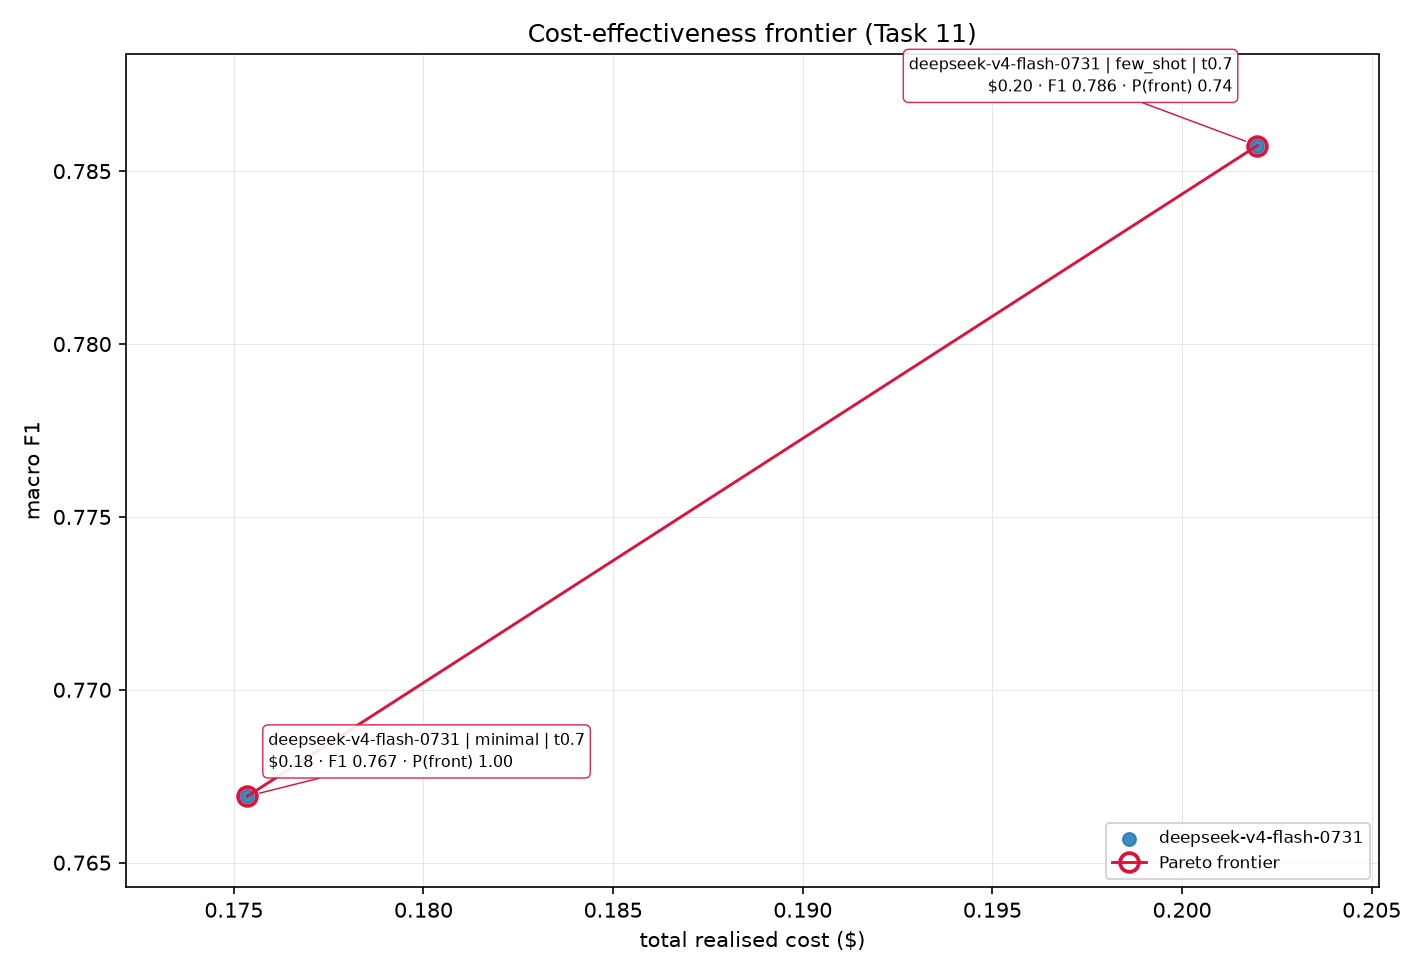

In [36]:
display(Image(filename=str(FIGURES / "frontier.png")))

## Failure sensitivity

In [37]:
print(report.failure_summary(data, scored_dir=SCORED))

80 runs total: 0 failed, 0 abstained (abstention is model behaviour, not a failure, and is not counted among the 0).
  0 context overflows, 0 timeouts (0 + 0 = 0).
context_overflow is genuinely ambiguous — inefficient search burning the context window (model behaviour) versus a site too large for a 128k window regardless of search quality (infrastructure); a sample of one model per failure type cannot separate the two readings, and this report does not resolve it.


In [38]:
comparisons = sens.compare_with_and_without_failures(data)
print(report.sensitivity_table(comparisons))

SENSITIVITY (D-D) — macro F1 with vs without failed (timed-out / context-overflow) runs
  config                                                          primary survivors    delta  n excl.
  openrouter/deepseek/deepseek-v4-flash-0731 | few_shot | t0.7      0.786     0.786    0.000        0
  openrouter/deepseek/deepseek-v4-flash-0731 | minimal | t0.7       0.767     0.767    0.000        0


## Runtime health

In [39]:
print(report.runtime_health_table(tel.runtime_health(scored_dir=SCORED)))

RUNTIME HEALTH — conformance, retries and token totals
  runs                       80
  schema-invalid output      0 (0.0% of runs)
  runs retried               5 (max attempts 2)
  step budget exhausted      0
  submit failed              0
  input tokens               9,707,754
  output tokens              1,116,960
  unattributable false pos.  29

Token totals are what make cost transferable: dollars are a function of this grid's prices on the day, tokens are not. 'unattributable false positives' are extractions matching no ground-truth row at all; score.py already fixes how precision treats them, and that decision is not restated here — the count is surfaced so the size of the affected population is visible.


## Cost per recovered opportunity

In [40]:
cost_rows = tel.cost_per_true_positive(data)
print(report.cost_per_tp_table(cost_rows))

COST PER TRUE POSITIVE — realised spend per recovered opportunity; the unit cost that survives a change of denominator
  config                                                            cost $    n TP    $ / TP  cost excl.
  openrouter/deepseek/deepseek-v4-flash-0731 | minimal | t0.7       0.1754     267    0.0007           0
  openrouter/deepseek/deepseek-v4-flash-0731 | few_shot | t0.7      0.2020     277    0.0007           0

A config that recovered nothing has an UNDEFINED unit cost ('—'), never 0 and never an infinity: inventing a number there would rank a config that found nothing as the cheapest on the page. 'cost excl.' carries frontier.py's caveat forward — runs that died before billing contribute nothing to the cost total, so these totals sit over unequal denominators.


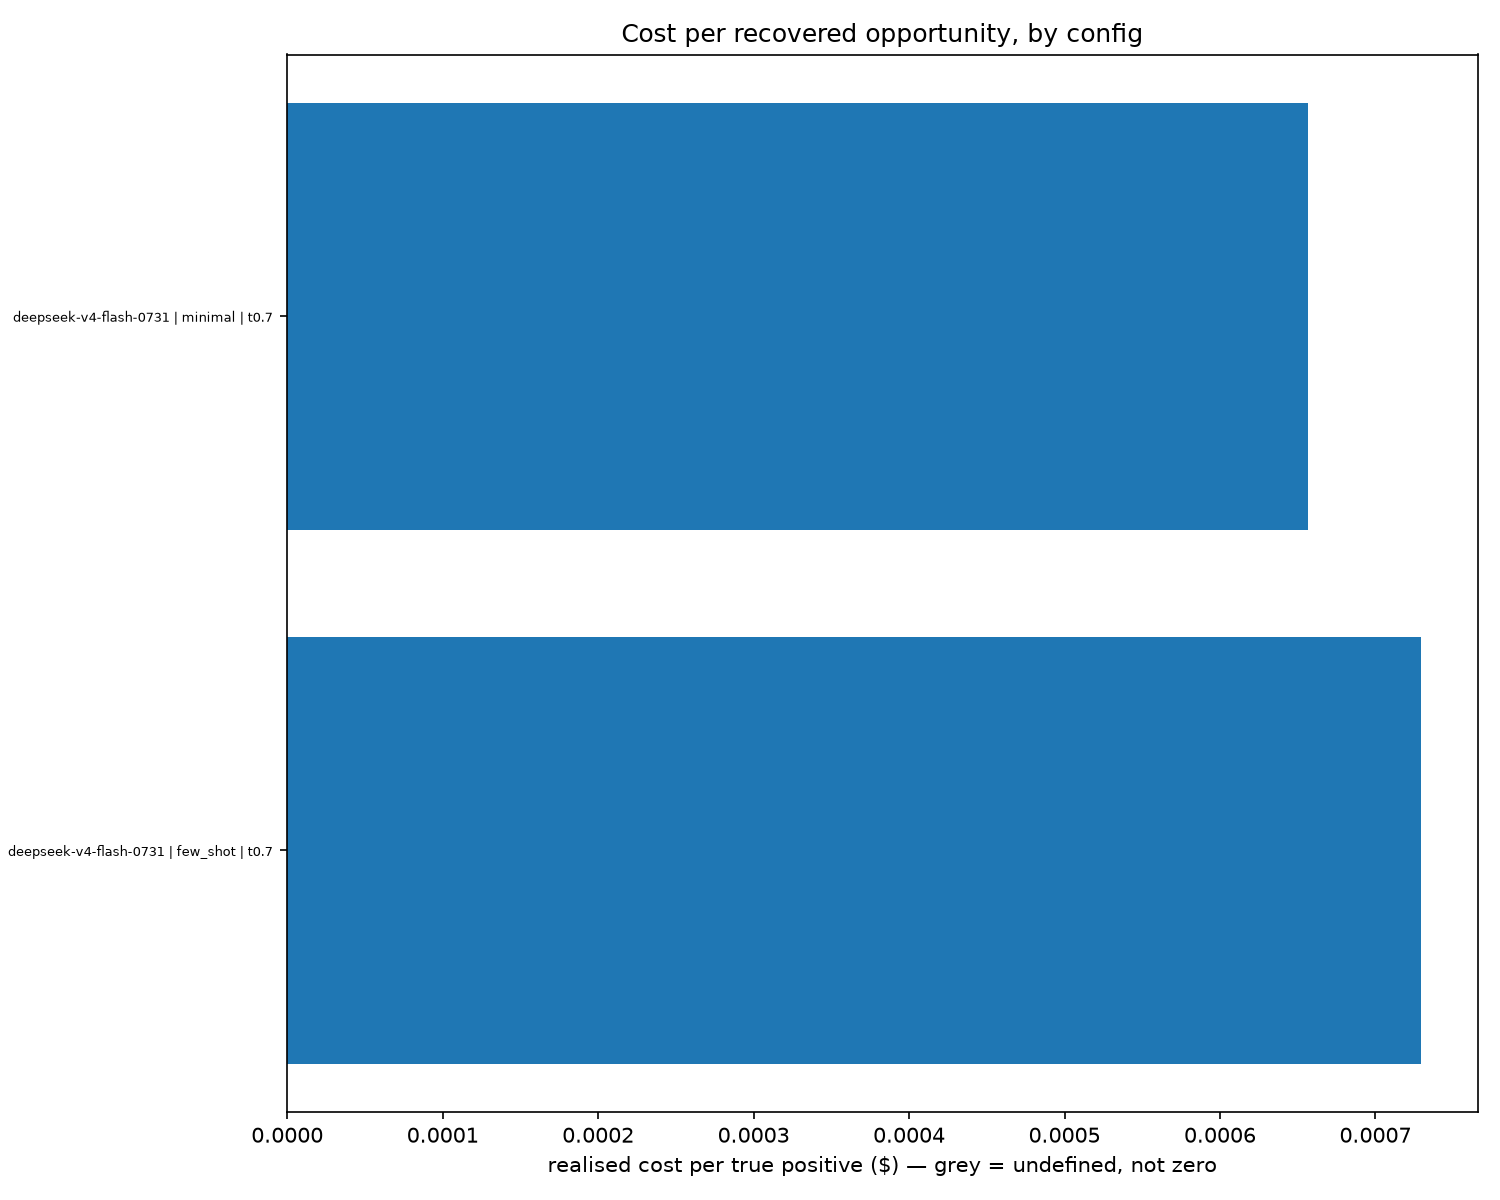

In [41]:
display(Image(filename=str(FIGURES / "cost_per_tp.png")))

## Latency

In [42]:
latency = tel.latency_profiles(data)
print(report.latency_table(latency))

LATENCY (seconds) — realised wall-clock per run
  group                      n runs  n defined      mean       p50        p95        max
  deepseek-v4-flash-0731         80         80     154.9     134.8      330.7      477.3

A run that died of context overflow has no defined latency (there is no completion time for a run that never completed) and is excluded from every statistic here; a timed-out run's latency IS defined but is the cap, not a measurement of the work, so it should be read as censored. A mean far above the p50 means the group is usually fast and occasionally catastrophic — the shape a mean alone would hide. Percentiles use numpy's default linear interpolation.


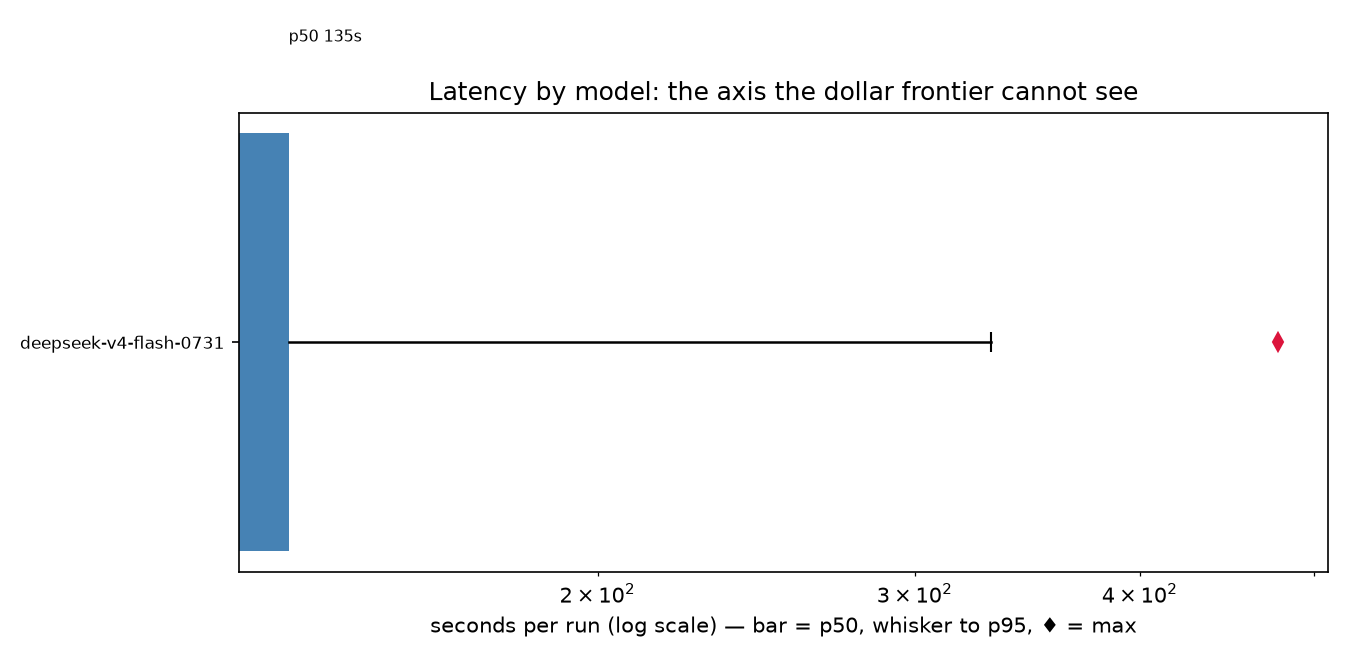

In [43]:
display(Image(filename=str(FIGURES / "latency.png")))

## Abstention

In [44]:
abstention = tel.abstention_profiles(data)
print(report.abstention_table(abstention))

ABSTENTION — runs that correctly reported nothing; never counted as failures (D-D), but recall is 0 for that funder either way
  group                      n runs  n abstained     rate
  deepseek-v4-flash-0731         80            0    0.000

'Found nothing' and 'found the wrong thing' are different product failures with different fixes; F1 alone pools them. A group with a high abstention rate has part of its F1 deficit explained by refusal rather than by error.


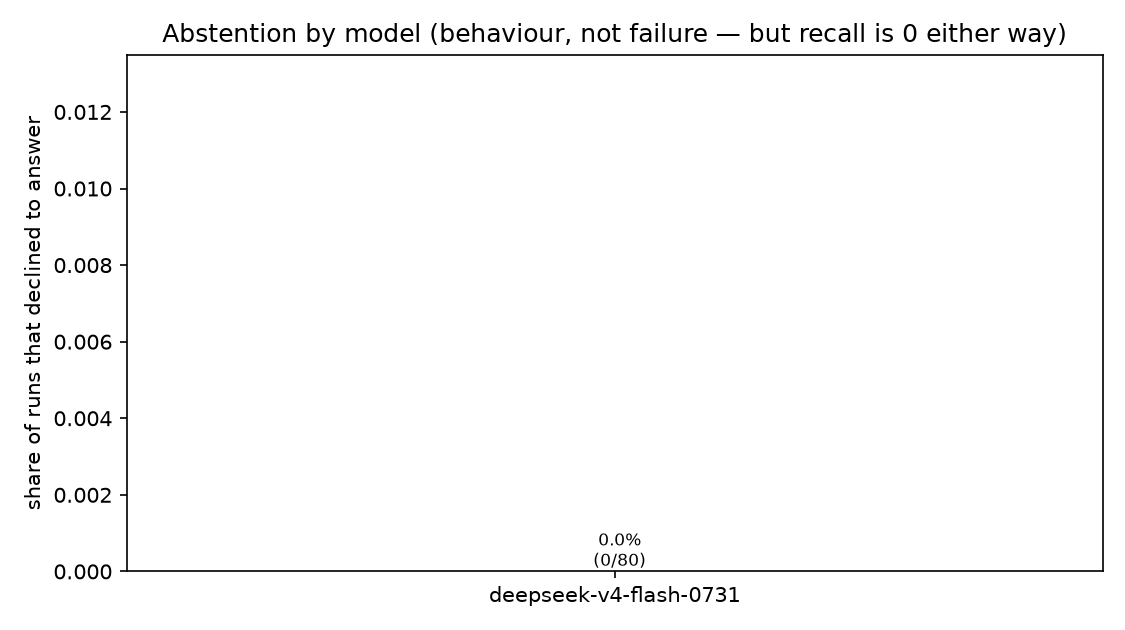

In [45]:
display(Image(filename=str(FIGURES / "abstention.png")))

## False-positive composition

In [46]:
fp_profiles = err.fp_reason_totals(data)
print(report.fp_reason_table(fp_profiles))

FALSE-POSITIVE COMPOSITION — counts, and each reason's share of that group's own false positives
  group                      n FP      fabricated_url          distractor     unlabelled_page           duplicate
  deepseek-v4-flash-0731       43            23 (53%)            13 (30%)             6 (14%)              1 (2%)

`ambiguous_title` is charged when a candidate's URL is shared by more than one ground-truth row and its title does not match — which is exactly the 'packed' funders of D-E (funders.py). Its size here is therefore the measure of how much of the structural-complexity result is scoring strictness rather than page difficulty; this table reports the composition and does not resolve that question.


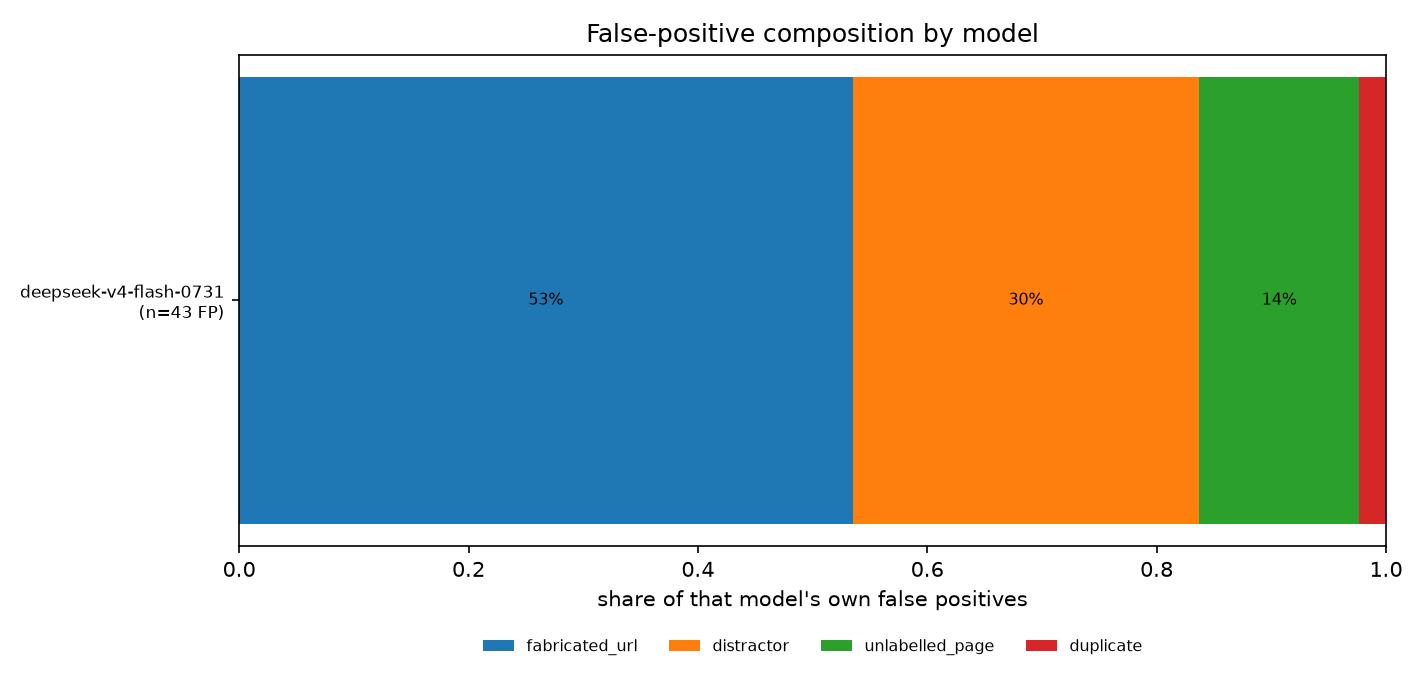

In [47]:
display(Image(filename=str(FIGURES / "fp_reasons.png")))

## Fabrication

In [48]:
fabrication = err.fabrication_totals(data)
print(report.fabrication_table(fabrication))

FABRICATION — invented items; a fabricated funding URL is the worst output class for this product, worse than a miss
  group                      n runs  n fabricated  runs fabricating  mean halluc.  n rate def.
  deepseek-v4-flash-0731         80            23                16        0.1096           80

'mean halluc.' averages only over runs with a DEFINED hallucination rate: a run that extracted nothing has no rate, and coercing that to 0 would read as scrupulous rather than silent. '—' means no run in the group had a defined rate.


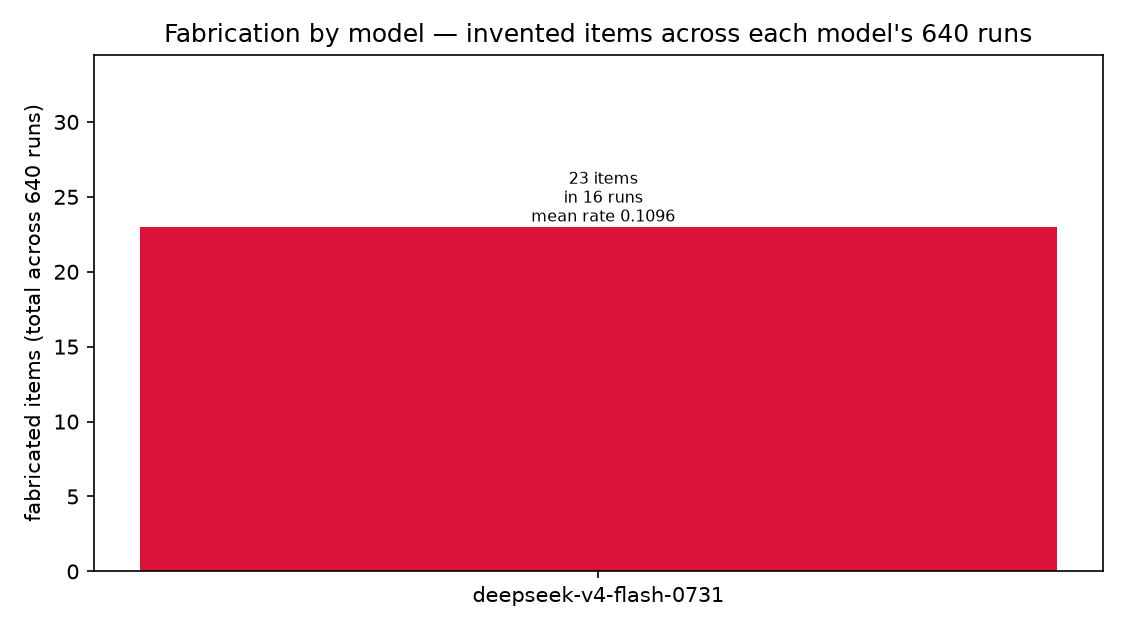

In [49]:
display(Image(filename=str(FIGURES / "fabrication.png")))

## RQ6: the tune-to-validation gap

In [50]:
print(report.generalisation_note(rq6))

GENERALISATION (RQ6) — locked configs, tune versus held-out validation
  config                                                           tuneF1    valF1      gap  tuneRank  valRank  tuneN  valN
  openrouter/deepseek/deepseek-v4-flash-0731 | few_shot | t0.7     0.7928   0.7857  -0.0071         1        1     16     8
  openrouter/deepseek/deepseek-v4-flash-0731 | minimal | t0.7      0.7863   0.7669  -0.0193         2        2     16     8

gap = validation macro F1 - tune macro F1; negative means the config did worse out of sample. The two means are over disjoint funder sets, so this is a difference of two independent macro means, NOT a paired difference: no Wilcoxon, no sign test and no bootstrap interval is reported here, because there is no funder present on both sides to pair on.
H4 — RANKING PRESERVED: every locked config holds the same rank on the held-out split as it held on tune. The configuration chosen on tune is still the better of the two out of sample, which is the claim t

In [51]:
print(f"mean gap across the locked configs: {rq6.mean_gap:.4f}")
print(f"ranking preserved                 : {rq6.ranking_preserved}")

mean gap across the locked configs: -0.0132
ranking preserved                 : True


## All tables as text

In [52]:
print((FIGURES / "report.txt").read_text())

################################################################################
LEADERBOARD
################################################################################
LEADERBOARD — macro F1 across all 2 configurations, best first
    #  config                                                          macroF1   macroP   macroR  funders
    1  openrouter/deepseek/deepseek-v4-flash-0731 | few_shot | t0.7      0.786    0.865    0.754        8
    2  openrouter/deepseek/deepseek-v4-flash-0731 | minimal | t0.7       0.767    0.841    0.739        8

################################################################################
STRUCTURED FIELD ACCURACY
################################################################################
STRUCTURED FIELD ACCURACY — exact match, pooled over opportunities; CONDITIONAL ON DETECTION (see 'n eval.')
  group                            deadlines   n eval.    amount_max_gbp   n eval.    amount_min_gbp   n eval.            status   n eval.
  deepse